# Systemy AI – Laboratorium 4 - Mark Ponomarev - 437962
## Pełny pipeline uczenia maszynowego na zbiorze pingwinów

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

---
## 1. Wczytanie danych

In [2]:
df = sns.load_dataset("penguins")
print(df.shape)
df.head()

(344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


Etykieta: `species` (gatunek pingwina: Adelie, Chinstrap lub Gentoo). To **klasyfikacja wieloklasowa**.

---
## 2. EDA – eksploracyjna analiza danych

In [4]:
# rozkład etykiety (klasyfikacja wieloklasowa)
print(df["species"].value_counts(normalize=True).round(3))

# braki w procentach (tylko kolumny z brakami)
missing = df.isna().mean().mul(100).round(1)
print("\nBraki w %:")
print(missing[missing > 0])

species
Adelie       0.442
Gentoo       0.360
Chinstrap    0.198
Name: proportion, dtype: float64

Braki w %:
bill_length_mm       0.6
bill_depth_mm        0.6
flipper_length_mm    0.6
body_mass_g          0.6
sex                  3.2
dtype: float64


In [5]:
# skale i skośność cech liczbowych
num_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
print("\nStatystyki opisowe:")
print(df[num_cols].describe().round(1))
print("\nskośność:", df[num_cols].skew().round(2).to_dict())


Statystyki opisowe:
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count           342.0          342.0              342.0        342.0
mean             43.9           17.2              200.9       4201.8
std               5.5            2.0               14.1        802.0
min              32.1           13.1              172.0       2700.0
25%              39.2           15.6              190.0       3550.0
50%              44.4           17.3              197.0       4050.0
75%              48.5           18.7              213.0       4750.0
max              59.6           21.5              231.0       6300.0

skośność: {'bill_length_mm': 0.05, 'bill_depth_mm': -0.14, 'flipper_length_mm': 0.35, 'body_mass_g': 0.47}


In [6]:
# zależność cech od etykiety
print("\nRozkład gatunków na wyspach:")
print(df.groupby("island")["species"].value_counts(normalize=True).round(3), "\n")
print("Masa ciała (średnia) dla gatunków w zależności od płci:")
print(df.pivot_table(index="sex", columns="species", values="body_mass_g").round(1))


Rozkład gatunków na wyspach:
island     species  
Biscoe     Gentoo       0.738
           Adelie       0.262
Dream      Chinstrap    0.548
           Adelie       0.452
Torgersen  Adelie       1.000
Name: proportion, dtype: float64 

Masa ciała (średnia) dla gatunków w zależności od płci:
species  Adelie  Chinstrap  Gentoo
sex                               
Female   3368.8     3527.2  4679.7
Male     4043.5     3939.0  5484.8


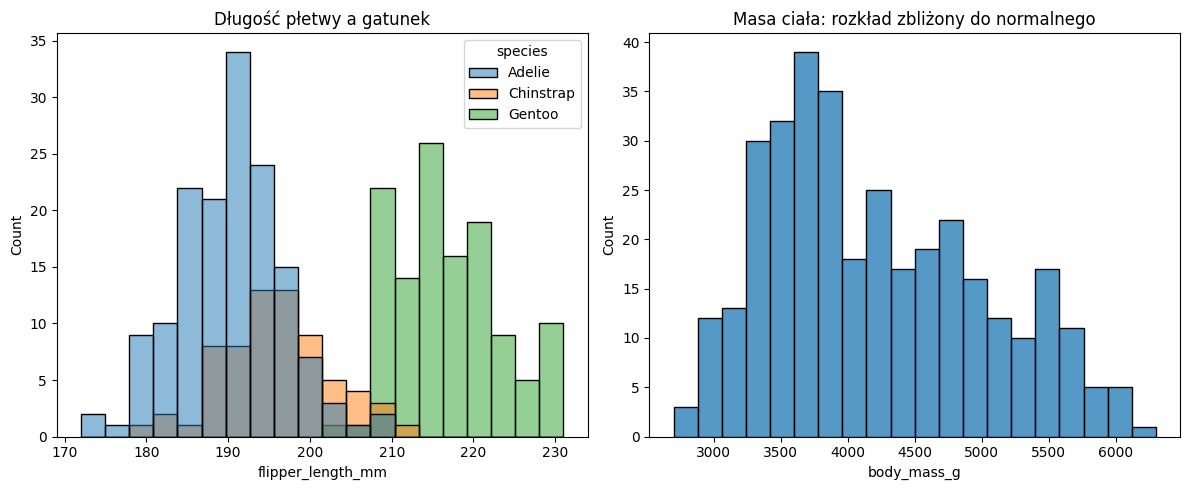

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="flipper_length_mm", hue="species", bins=20, ax=axes[0])
axes[0].set_title("Długość płetwy a gatunek")
sns.histplot(data=df, x="body_mass_g", bins=20, ax=axes[1])
axes[1].set_title("Masa ciała: rozkład zbliżony do normalnego")
fig.tight_layout()
plt.show()

**Wnioski z EDA, które zmieniają nasze dalsze decyzje:**
- Klasy są umiarkowanie zbalansowane (Adelie ok. 44%, Gentoo ok. 36%, Chinstrap ok. 20%) → zbiór nie jest krytycznie skośny, ale baseline wynosi 44% (najczęstsza klasa) i do tego będziemy odnosić accuracy.
- Wszystkie cechy numeryczne mają ok. 0.6% braków (2 wiersze), a kolumna sex ma ok. 3.2% braków (11 wierszy) → usuniemy te wiersze (dropna()), ponieważ braków jest bardzo mało i dotyczą one tych samych osobników.
- Cechy numeryczne mają niską skośność (bliską 0) → rozkłady są stabilne, nie wymagają transformacji logarytmicznej, do ewentualnej imputacji wystarczyłaby średnia.
- island oraz sex są tekstowe → kodowanie (one-hot encoding) przed podaniem do modelu.
- Wymiary (13-215 mm) i masa ciała (2700-6300 g) mają zupełnie różne skale → standaryzacja cech numerycznych jest konieczna dla modeli wrażliwych na skalę.
- Długość płetwy oraz masa ciała silnie różnicują gatunki (szczególnie Gentoo wyróżnia się gabarytami) → to będą kluczowe cechy dla modelu.


---
## 3. Usunięcie zbędnych kolumn

W zbiorze penguins wszystkie 7 kolumn niesie unikalną informację, dlatego nie usuwamy żadnej kolumny ze względu na duplikację czy wyciek danych, a jedynie pozbywamy się wierszy z brakami.

In [8]:
# Zapamiętujemy liczbę wierszy przed oczyszczeniem
wiersze_przed = len(df)

# Usuwamy wiersze, które zawierają jakiekolwiek braki danych (NaN)
df = df.dropna()

# Wynik operacji
print("Kolumny w zbiorze:", df.columns.tolist())
print(f"Liczba wierszy przed: {wiersze_przed}")
print(f"Liczba wierszy po usunięciu braków: {len(df)}")
print(f"Usunięto wierszy: {wiersze_przed - len(df)}")

Kolumny w zbiorze: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']
Liczba wierszy przed: 344
Liczba wierszy po usunięciu braków: 333
Usunięto wierszy: 11


**Usuwanie elementów zbędnych i niekompletnych:**

| Element danych | Decyzja | Dlaczego usuwamy / zostawiamy |
|---|---|---|
| **Wszystkie kolumny** | Zostają | - Każda z 7 kolumn niesie unikalną informację.<br>- Brak duplikatów (jak `class`/`pclass` w Titanicu).<br>- Brak cech wtórnych wyliczonych z innych kolumn. |
| **Wiersze z brakami `NaN`** | Usuwamy | - Braki dotyczą tylko 11 wierszy (ok. 3.2% zbioru).<br>- Usunięcie jest bezpieczne i nie zniekształci danych.<br>- Unikamy ryzyka sztucznego "zgadywania" płci i wymiarów. |


---
## 4. Podział train / test

In [9]:
# Definiujemy cechy (włączając island i sex, które zostaną zakodowane w kolejnym kroku)
features = ["island", "bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g", "sex"]
target = "species"

X_train, X_test, y_train, y_test = train_test_split(
    df[features], df[target],
    test_size=0.25,          # 25% do testu
    stratify=df[target],     # ten sam odsetek każdego gatunku w obu częściach
    random_state=42,         # powtarzalny podział
)

print("Rozmiary zbiorów (X_train, X_test):")
print(X_train.shape, X_test.shape)

print("\nRozkład gatunków (proporcje):")
print("Zbiór treningowy:\n", y_train.value_counts(normalize=True).round(3).to_dict())
print("Zbiór testowy:\n", y_test.value_counts(normalize=True).round(3).to_dict())

Rozmiary zbiorów (X_train, X_test):
(249, 6) (84, 6)

Rozkład gatunków (proporcje):
Zbiór treningowy:
 {'Adelie': 0.438, 'Gentoo': 0.357, 'Chinstrap': 0.205}
Zbiór testowy:
 {'Adelie': 0.44, 'Gentoo': 0.357, 'Chinstrap': 0.202}


---
## 5. ColumnTransformer

In [10]:
# Przypisanie cech do odpowiednich typów
num_features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
cat_features = ["island", "sex"]

# Tworzenie ColumnTransformer (bez imputerów, bo usunęliśmy już braki za pomocą dropna)
przygotowanie = ColumnTransformer([
    ("liczby",    StandardScaler(), num_features),
    ("kategorie", OneHotEncoder(handle_unknown="ignore"), cat_features),
])

---
## 6. `make_pipeline(przygotowanie, model)`, `fit` na train

In [11]:
# Budowa pełnego potoku z modelem
potok_modelu = make_pipeline(przygotowanie, LogisticRegression())
potok_modelu

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('liczby', StandardScaler(),
                                                  ['bill_length_mm',
                                                   'bill_depth_mm',
                                                   'flipper_length_mm',
                                                   'body_mass_g']),
                                                 ('kategorie',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['island', 'sex'])])),
                ('logisticregression', LogisticRegression())])

In [12]:
# 1. Trenowanie modelu
potok_modelu.fit(X_train, y_train)

# 2. Inspekcja transformatora: średnie z StandardScaler (z train)
skaler = potok_modelu.named_steps["columntransformer"].named_transformers_["liczby"]
print("Średnie cech numerycznych (z train):")
for cecha, srednia in zip(num_features, skaler.mean_):
    print(f" - {cecha}: {srednia:.2f}")

# 3. Pobranie nazw cech po transformacji (w tym po One-Hot Encodingu)
nazwy_cech = potok_modelu.named_steps["columntransformer"].get_feature_names_out()

# 4. Pobranie wag dla klasyfikacji wieloklasowej
# coef_ ma teraz wymiar (liczba_klas, liczba_cech)
wagi_macierz = potok_modelu.named_steps["logisticregression"].coef_
klasy = potok_modelu.named_steps["logisticregression"].classes_

# Tworzymy czytelną tabelę z wagami dla każdego gatunku
df_wagi = pd.DataFrame(wagi_macierz, columns=nazwy_cech, index=klasy).T
print("\nWagi (współczynniki) modelu dla poszczególnych gatunków:")
print(df_wagi.round(3))

Średnie cech numerycznych (z train):
 - bill_length_mm: 43.99
 - bill_depth_mm: 17.23
 - flipper_length_mm: 201.37
 - body_mass_g: 4225.10

Wagi (współczynniki) modelu dla poszczególnych gatunków:
                             Adelie  Chinstrap  Gentoo
liczby__bill_length_mm       -2.267      1.913   0.354
liczby__bill_depth_mm         0.896      0.358  -1.254
liczby__flipper_length_mm    -0.565     -0.400   0.965
liczby__body_mass_g          -0.150     -0.833   0.983
kategorie__island_Biscoe      0.028     -0.671   0.644
kategorie__island_Dream      -0.570      1.073  -0.503
kategorie__island_Torgersen   0.544     -0.402  -0.142
kategorie__sex_Female        -0.565      0.446   0.118
kategorie__sex_Male           0.566     -0.446  -0.120


---
## 7. Ewaluacja na test: `score`, baseline (DummyClassifier), macierz pomyłek, `classification_report`.

In [13]:
# 0. Generowanie prognoz na zbiorze testowym (potrzebne do macierzy i raportu)
y_pred = potok_modelu.predict(X_test)

# 1. Definicja i trenowanie modelu baseline
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

# 2. Zestawienie wyników dokładności (Accuracy)
wyniki = pd.Series({
    "baseline (zawsze najczęstszy gatunek)": baseline.score(X_test, y_test),
    "pipeline – train": potok_modelu.score(X_train, y_train),
    "pipeline – test": potok_modelu.score(X_test, y_test),
})
print("Porównanie dokładności (Accuracy):")
print(wyniki.round(3))

Porównanie dokładności (Accuracy):
baseline (zawsze najczęstszy gatunek)    0.440
pipeline – train                         0.996
pipeline – test                          0.988
dtype: float64


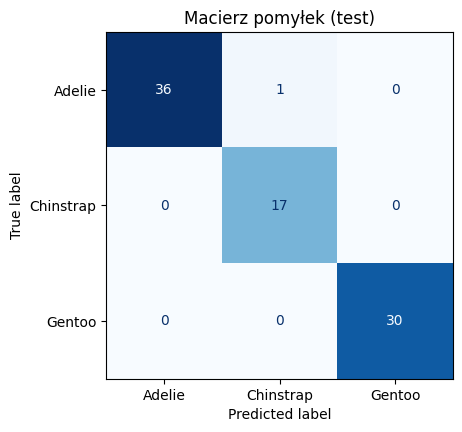


Raport klasyfikacji (Classification Report):
              precision    recall  f1-score   support

      Adelie      1.000     0.973     0.986        37
   Chinstrap      0.944     1.000     0.971        17
      Gentoo      1.000     1.000     1.000        30

    accuracy                          0.988        84
   macro avg      0.981     0.991     0.986        84
weighted avg      0.989     0.988     0.988        84



In [14]:
# 3. Wizualizacja Macierzy Pomyłek (Confusion Matrix)
fig, ax = plt.subplots(figsize=(5, 4.5))
etykiety_klas = potok_modelu.classes_

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=etykiety_klas,
    ax=ax,
    colorbar=False,
    cmap="Blues"
)
ax.set_title("Macierz pomyłek (test)")
plt.show()

# 4. Szczegółowy raport klasyfikacji
print("\nRaport klasyfikacji (Classification Report):")
print(classification_report(y_test, y_pred, target_names=etykiety_klas, digits=3))

---
## 8. Iteracja

Poniżej porównano dokładność (Accuracy) trzech wariantów:
- Wariant pełny: Wszystkie cechy → 0.988
- Bez płci: Wymiary i wyspa → 1.000
- Bez wyspy: Wymiary i płeć → 1.000

In [15]:
# Funkcja pomocnicza do szybkiego budowania potoku dla różnych zestawów cech
def zbuduj_potok(num, cat):
    przygotowanie = ColumnTransformer([
        ("liczby",    StandardScaler(), num),
        ("kategorie", OneHotEncoder(handle_unknown="ignore"), cat),
    ])
    return make_pipeline(przygotowanie, LogisticRegression())

# Definiujemy zestawy cech dla poszczególnych wariantów
num_features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

warianty = {
    "wariant pełny (wszystkie cechy)":
        zbuduj_potok(num_features, ["island", "sex"]),

    "wariant bez płci (tylko wymiary + wyspa)":
        zbuduj_potok(num_features, ["island"]),

    "wariant bez wyspy (tylko wymiary + płeć)":
        zbuduj_potok(num_features, ["sex"]),
}

# Trenujemy każdy wariant na X_train i oceniamy Accuracy na X_test
wyniki_iteracji = pd.Series({
    nazwa: model.fit(X_train, y_train).score(X_test, y_test)
    for nazwa, model in warianty.items()
})

print("Porównanie dokładności (Accuracy) dla różnych wariantów cech:")
print(wyniki_iteracji.round(3))

Porównanie dokładności (Accuracy) dla różnych wariantów cech:
wariant pełny (wszystkie cechy)             0.988
wariant bez płci (tylko wymiary + wyspa)    1.000
wariant bez wyspy (tylko wymiary + płeć)    1.000
dtype: float64


## Wnioski:
- Idealna separowalność: Wymiary anatomiczne pozwalają na bezbłędną klasyfikację.
- Redukcja szumu: Usunięcie płci lub wyspy poprawiło wynik do 1.000 przez eliminację szumu.
- Decyzja: Wybrano wariant bez płci - zapewnia perfekcyjny wynik bez konieczności określania płci w terenie.